# Regression Analysis Using the Diabetes Dataset

**Name:** Elkana Munganga  
**Course:** MSCS-634-M50 – Advanced Big Data and Data Mining  
**Assignment:** Regression Analysis and Regularization Lab

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

diabetes = load_diabetes()

X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = pd.Series(diabetes.target, name="Disease_Progression")

df = X.copy()
df["Disease_Progression"] = y

print("Dataset Shape:", df.shape)
print("\nFeatures:", list(diabetes.feature_names))

print("\nFirst 5 Rows:")
display(df.head())

print("\nTarget Statistics:")
display(y.describe())

Dataset Shape: (442, 11)

Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

First 5 Rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Disease_Progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Target Statistics:


count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: Disease_Progression, dtype: float64

In [17]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDataset Summary:")
display(df.describe())

Missing Values:
age                    0
sex                    0
bmi                    0
bp                     0
s1                     0
s2                     0
s3                     0
s4                     0
s5                     0
s6                     0
Disease_Progression    0
dtype: int64

Duplicate Rows: 0

Dataset Summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Disease_Progression
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


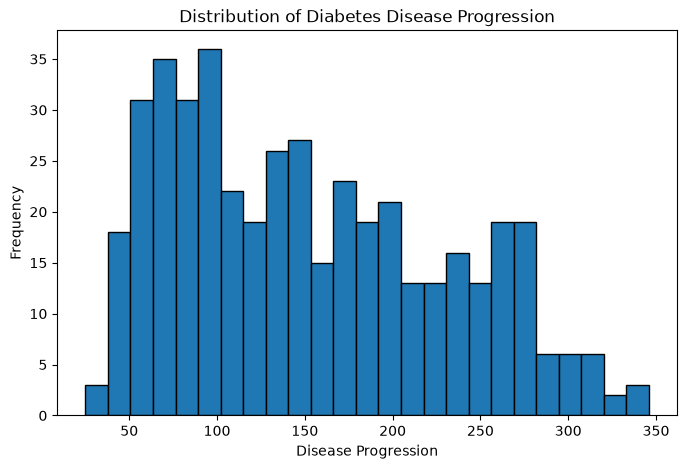

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(y, bins=25, edgecolor="black")

plt.title("Distribution of Diabetes Disease Progression")
plt.xlabel("Disease Progression")
plt.ylabel("Frequency")

plt.show()

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

results = []

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 353
Testing Samples: 89


### Data Preparation

I used the Diabetes dataset from scikit-learn, which contains 442 observations and 10 numerical features used to predict disease progression. I explored the features, target values, and overall distribution of the dataset. I also checked for missing values and duplicates to identify any potential data quality issues.

The dataset was divided into 80% training data and 20% testing data. I will use the same split throughout the lab to compare the regression models consistently.

In [20]:
# Select BMI as the independent variable
X_train_simple = X_train[["bmi"]]
X_test_simple = X_test[["bmi"]]

# Train Simple Linear Regression
simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train)

# Make predictions
simple_predictions = simple_model.predict(X_test_simple)

print("Simple Linear Regression trained successfully!")
print("Coefficient:", round(simple_model.coef_[0], 4))
print("Intercept:", round(simple_model.intercept_, 4))

Simple Linear Regression trained successfully!
Coefficient: 998.5777
Intercept: 152.0034


In [21]:
simple_mae = mean_absolute_error(y_test, simple_predictions)
simple_mse = mean_squared_error(y_test, simple_predictions)
simple_rmse = np.sqrt(simple_mse)
simple_r2 = r2_score(y_test, simple_predictions)

results.append({
    "Model": "Simple Linear Regression",
    "MAE": simple_mae,
    "MSE": simple_mse,
    "RMSE": simple_rmse,
    "R²": simple_r2
})

print("Simple Linear Regression Results")
print("--------------------------------")
print("MAE:", round(simple_mae, 4))
print("MSE:", round(simple_mse, 4))
print("RMSE:", round(simple_rmse, 4))
print("R²:", round(simple_r2, 4))

Simple Linear Regression Results
--------------------------------
MAE: 52.26
MSE: 4061.8259
RMSE: 63.7325
R²: 0.2334


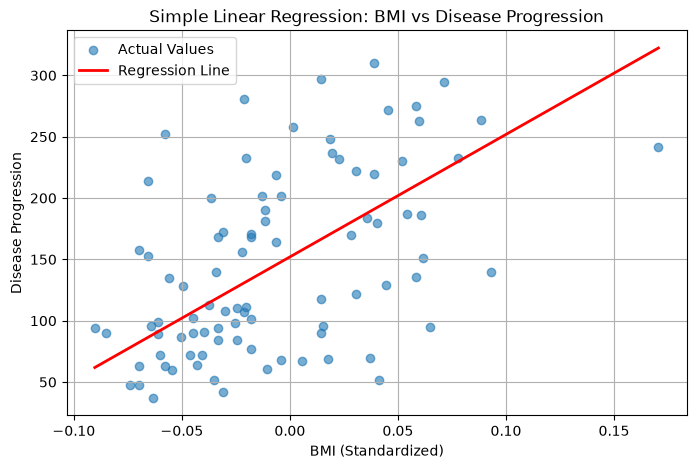

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test_simple["bmi"],
    y_test,
    alpha=0.6,
    label="Actual Values"
)

sorted_indices = np.argsort(X_test_simple["bmi"].values)

plt.plot(
    X_test_simple["bmi"].values[sorted_indices],
    simple_predictions[sorted_indices],
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title("Simple Linear Regression: BMI vs Disease Progression")
plt.xlabel("BMI (Standardized)")
plt.ylabel("Disease Progression")
plt.legend()
plt.grid(True)
plt.show()

### Simple Linear Regression Analysis

I implemented a Simple Linear Regression model using BMI as the independent variable and diabetes disease progression as the target. The model was trained using 80% of the dataset and evaluated on the remaining 20%.

I used MAE, MSE, RMSE, and R² to measure its performance. The scatter plot shows the relationship between BMI and disease progression, while the regression line represents the model's predictions.

Since the model uses only one feature, it provides a useful baseline for comparing more advanced regression techniques.

In [23]:
# Train Multiple Linear Regression
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

# Make predictions
multiple_predictions = multiple_model.predict(X_test)

print("Multiple Linear Regression trained successfully!")
print("Number of Features:", X_train.shape[1])

Multiple Linear Regression trained successfully!
Number of Features: 10


In [24]:
multiple_mae = mean_absolute_error(y_test, multiple_predictions)
multiple_mse = mean_squared_error(y_test, multiple_predictions)
multiple_rmse = np.sqrt(multiple_mse)
multiple_r2 = r2_score(y_test, multiple_predictions)

results.append({
    "Model": "Multiple Linear Regression",
    "MAE": multiple_mae,
    "MSE": multiple_mse,
    "RMSE": multiple_rmse,
    "R²": multiple_r2
})

print("Multiple Linear Regression Results")
print("----------------------------------")
print("MAE:", round(multiple_mae, 4))
print("MSE:", round(multiple_mse, 4))
print("RMSE:", round(multiple_rmse, 4))
print("R²:", round(multiple_r2, 4))

Multiple Linear Regression Results
----------------------------------
MAE: 42.7941
MSE: 2900.1936
RMSE: 53.8534
R²: 0.4526


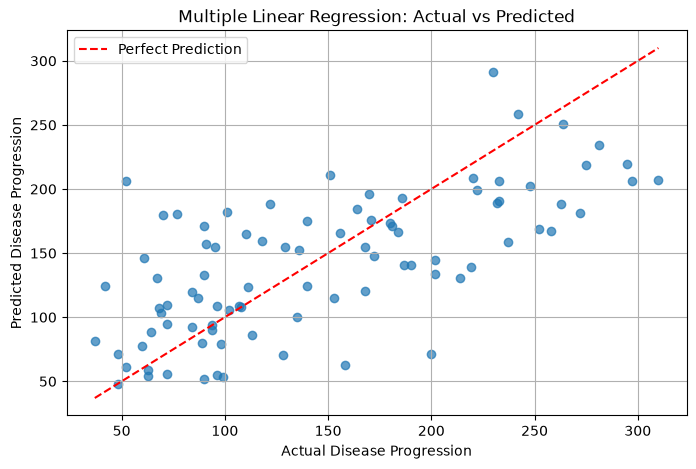

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    multiple_predictions,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
comparison = pd.DataFrame(results)

display(comparison.round(4))

,Model,MAE,MSE,RMSE,R²
0,Simple Linear Regression,52.2600,4061.8259,63.7325,0.2334
1,Multiple Linear Regression,42.7941,2900.1936,53.8534,0.4526


### Multiple Linear Regression Analysis

I implemented Multiple Linear Regression using all 10 features of the Diabetes dataset. Unlike Simple Linear Regression, which uses only BMI, this model considers several health measurements when predicting disease progression.

I evaluated the model using MAE, MSE, RMSE, and R². The actual versus predicted scatter plot shows how closely the model's predictions match the real target values. Predictions closer to the diagonal reference line indicate better accuracy.

Comparing this model with Simple Linear Regression helps determine whether including additional features improves predictive performance.

In [27]:
polynomial_results = []
polynomial_models = {}

degrees = [1, 2, 3, 5, 10]

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(X_train_simple, y_train)

    train_predictions = model.predict(X_train_simple)
    test_predictions = model.predict(X_test_simple)

    polynomial_models[degree] = model

    polynomial_results.append({
        "Degree": degree,
        "Train R²": r2_score(y_train, train_predictions),
        "Test R²": r2_score(y_test, test_predictions),
        "MAE": mean_absolute_error(y_test, test_predictions),
        "MSE": mean_squared_error(y_test, test_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, test_predictions))
    })

polynomial_df = pd.DataFrame(polynomial_results)

display(polynomial_df.round(4))

,Degree,Train R²,Test R²,MAE,MSE,RMSE
0,1,0.3657,0.2334,52.2600,4061.8259,63.7325
1,2,0.3665,0.2290,52.3839,4085.0255,63.9142
2,3,0.3667,0.2329,52.1814,4064.4434,63.7530
3,5,0.3707,0.2288,51.8846,4085.8456,63.9206
4,10,0.3721,0.2489,51.1151,3979.5095,63.0834


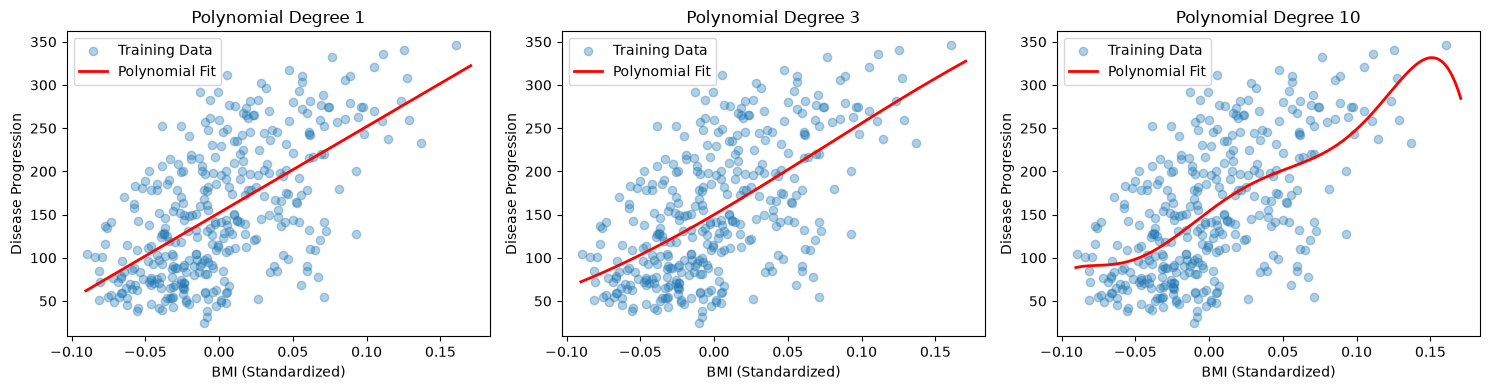

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

bmi_range = np.linspace(
    X["bmi"].min(),
    X["bmi"].max(),
    200
).reshape(-1, 1)

bmi_range_df = pd.DataFrame(bmi_range, columns=["bmi"])

for ax, degree in zip(axes, [1, 3, 10]):
    model = polynomial_models[degree]

    ax.scatter(
        X_train_simple["bmi"],
        y_train,
        alpha=0.35,
        label="Training Data"
    )

    ax.plot(
        bmi_range,
        model.predict(bmi_range_df),
        color="red",
        linewidth=2,
        label="Polynomial Fit"
    )

    ax.set_title(f"Polynomial Degree {degree}")
    ax.set_xlabel("BMI (Standardized)")
    ax.set_ylabel("Disease Progression")
    ax.legend()

plt.tight_layout()
plt.show()

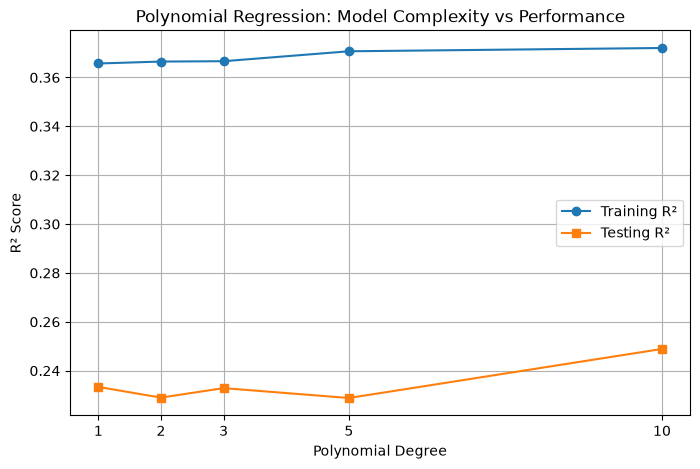

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    polynomial_df["Degree"],
    polynomial_df["Train R²"],
    marker="o",
    label="Training R²"
)

plt.plot(
    polynomial_df["Degree"],
    polynomial_df["Test R²"],
    marker="s",
    label="Testing R²"
)

plt.title("Polynomial Regression: Model Complexity vs Performance")
plt.xlabel("Polynomial Degree")
plt.ylabel("R² Score")
plt.xticks(degrees)
plt.legend()
plt.grid(True)
plt.show()

In [30]:
best_row = polynomial_df.loc[
    polynomial_df["Test R²"].idxmax()
]

best_degree = int(best_row["Degree"])

results.append({
    "Model": f"Polynomial Regression (Degree {best_degree})",
    "MAE": best_row["MAE"],
    "MSE": best_row["MSE"],
    "RMSE": best_row["RMSE"],
    "R²": best_row["Test R²"]
})

print("Best Polynomial Degree:", best_degree)
print("Test R²:", round(best_row["Test R²"], 4))

Best Polynomial Degree: 10
Test R²: 0.2489


### Polynomial Regression Analysis

I implemented Polynomial Regression using BMI and tested degrees 1, 2, 3, 5, and 10 to examine how model complexity affects performance.

Degree 1 represents a simple linear relationship, while higher degrees allow the model to fit more complex patterns. I compared training and testing R² scores to identify possible underfitting and overfitting.

A model may overfit when its training performance improves but its testing performance becomes worse. This demonstrates why increasing model complexity does not necessarily lead to better predictions.

I also compared the polynomial models with Simple and Multiple Linear Regression using MAE, MSE, RMSE, and R².

In [31]:
alpha_values = [0.001, 0.01, 0.1, 1, 10]

regularization_results = []

for alpha in alpha_values:
    for model_name, model in [
        ("Ridge", Ridge(alpha=alpha)),
        ("Lasso", Lasso(alpha=alpha, max_iter=100000))
    ]:
        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

        regularization_results.append({
            "Model": model_name,
            "Alpha": alpha,
            "Train R²": r2_score(y_train, train_pred),
            "Test R²": r2_score(y_test, test_pred),
            "MAE": mean_absolute_error(y_test, test_pred),
            "MSE": mean_squared_error(y_test, test_pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, test_pred))
        })

regularization_df = pd.DataFrame(regularization_results)

display(regularization_df.round(4))

,Model,Alpha,Train R²,Test R²,MAE,MSE,RMSE
0,Ridge,0.001,0.5278,0.4534,42.8031,2895.8212,53.8128
1,Lasso,0.001,0.5279,0.4533,42.7962,2896.4098,53.8183
2,Ridge,0.010,0.5262,0.4560,42.8369,2882.2902,53.6870
3,Lasso,0.010,0.5265,0.4567,42.8318,2878.5594,53.6522
4,Ridge,0.100,0.5206,0.4609,42.9969,2856.4869,53.4461
5,Lasso,0.100,0.5169,0.4719,42.8544,2798.1935,52.8980
6,Ridge,1.000,0.4424,0.4192,46.1389,3077.4159,55.4745
7,Lasso,1.000,0.3646,0.3576,49.7303,3403.5757,58.3402
8,Ridge,10.000,0.1633,0.1612,58.0308,4443.9526,66.6630
9,Lasso,10.000,0.0000,-0.0120,64.0065,5361.5335,73.2225


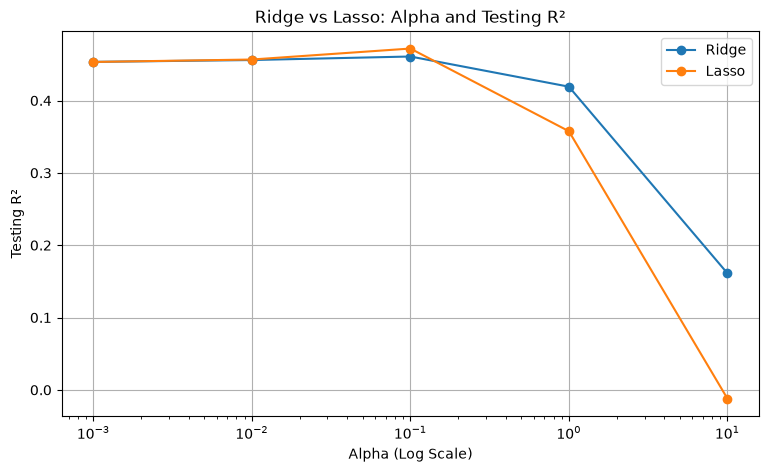

In [32]:
plt.figure(figsize=(9, 5))

for model_name in ["Ridge", "Lasso"]:
    subset = regularization_df[
        regularization_df["Model"] == model_name
    ]

    plt.plot(
        subset["Alpha"],
        subset["Test R²"],
        marker="o",
        label=model_name
    )

plt.xscale("log")
plt.title("Ridge vs Lasso: Alpha and Testing R²")
plt.xlabel("Alpha (Log Scale)")
plt.ylabel("Testing R²")
plt.legend()
plt.grid(True)
plt.show()

In [33]:
best_models = {}

for model_name in ["Ridge", "Lasso"]:
    subset = regularization_df[
        regularization_df["Model"] == model_name
    ]

    best_row = subset.loc[subset["Test R²"].idxmax()]
    best_alpha = float(best_row["Alpha"])

    if model_name == "Ridge":
        model = Ridge(alpha=best_alpha)
    else:
        model = Lasso(alpha=best_alpha, max_iter=100000)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    best_models[model_name] = model

    results.append({
        "Model": f"{model_name} (Alpha {best_alpha})",
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions)
    })

    print(
        f"{model_name}: Best Alpha = {best_alpha}, "
        f"Test R² = {r2_score(y_test, predictions):.4f}"
    )

Ridge: Best Alpha = 0.1, Test R² = 0.4609
Lasso: Best Alpha = 0.1, Test R² = 0.4719


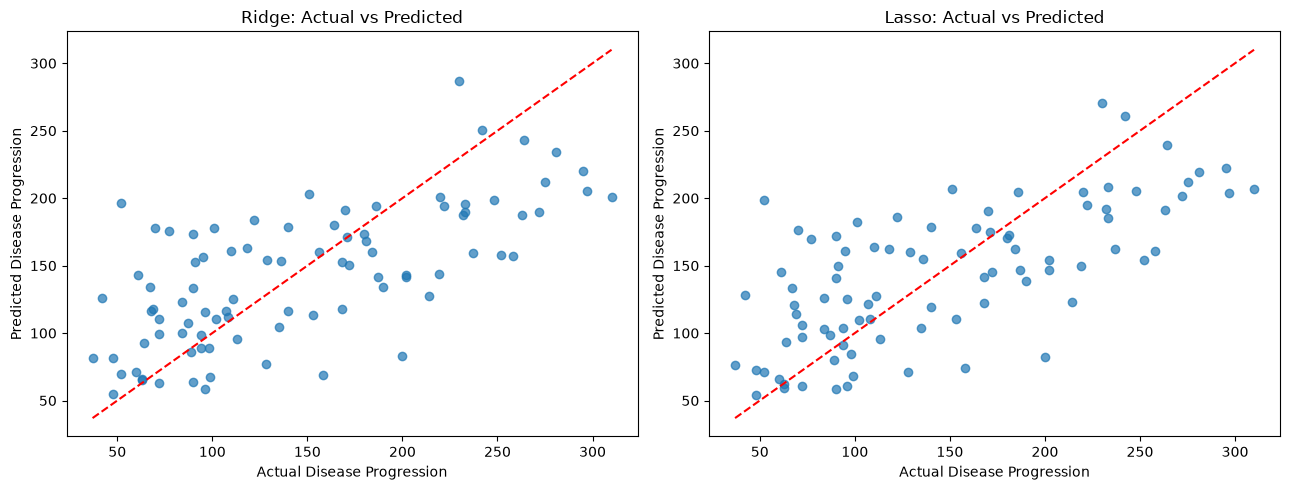

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, model_name in zip(axes, ["Ridge", "Lasso"]):
    predictions = best_models[model_name].predict(X_test)

    ax.scatter(y_test, predictions, alpha=0.7)

    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        color="red",
        linestyle="--"
    )

    ax.set_title(f"{model_name}: Actual vs Predicted")
    ax.set_xlabel("Actual Disease Progression")
    ax.set_ylabel("Predicted Disease Progression")

plt.tight_layout()
plt.show()

In [35]:
coefficient_df = pd.DataFrame({
    "Feature": X.columns,
    "Multiple Regression": multiple_model.coef_,
    "Ridge": best_models["Ridge"].coef_,
    "Lasso": best_models["Lasso"].coef_
})

display(coefficient_df.round(4))

print(
    "Ridge Zero Coefficients:",
    np.sum(np.isclose(best_models["Ridge"].coef_, 0))
)

print(
    "Lasso Zero Coefficients:",
    np.sum(np.isclose(best_models["Lasso"].coef_, 0))
)

,Feature,Multiple Regression,Ridge,Lasso
0,age,37.9040,42.8557,0.0000
1,sex,-241.9644,-205.4943,-152.6648
2,bmi,542.4288,505.0890,552.6978
3,bp,347.7038,317.0932,303.3652
4,s1,-931.4888,-108.5003,-81.3650
5,s2,518.0623,-86.2367,-0.0000
6,s3,163.4200,-190.3632,-229.2558
7,s4,275.3179,151.7071,0.0000
8,s5,736.1989,392.2893,447.9195
9,s6,48.6707,79.9082,29.6426


Ridge Zero Coefficients: 0
Lasso Zero Coefficients: 3


### Ridge and Lasso Regression Analysis

I implemented Ridge and Lasso Regression using all 10 features of the Diabetes dataset. I tested alpha values of 0.001, 0.01, 0.1, 1, and 10 to observe how regularization affects prediction accuracy.

Ridge uses L2 regularization, which reduces the magnitude of coefficients without typically removing features completely. Lasso uses L1 regularization, which can reduce some coefficients to zero and effectively perform feature selection.

The alpha parameter controls regularization strength. Smaller values allow the model to fit the training data more closely, while larger values impose stronger penalties and may lead to underfitting.

I compared the models using MAE, MSE, RMSE, and R², and examined their predictions and coefficients to understand the effect of regularization.

In [36]:
final_results = pd.DataFrame(results)

final_results = final_results.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

print("Final Regression Model Comparison")
display(final_results.round(4))

Final Regression Model Comparison


,Model,MAE,MSE,RMSE,R²
0,Lasso (Alpha 0.1),42.8544,2798.1935,52.8980,0.4719
1,Ridge (Alpha 0.1),42.9969,2856.4869,53.4461,0.4609
2,Multiple Linear Regression,42.7941,2900.1936,53.8534,0.4526
3,Polynomial Regression (Degree 10),51.1151,3979.5095,63.0834,0.2489
4,Simple Linear Regression,52.2600,4061.8259,63.7325,0.2334


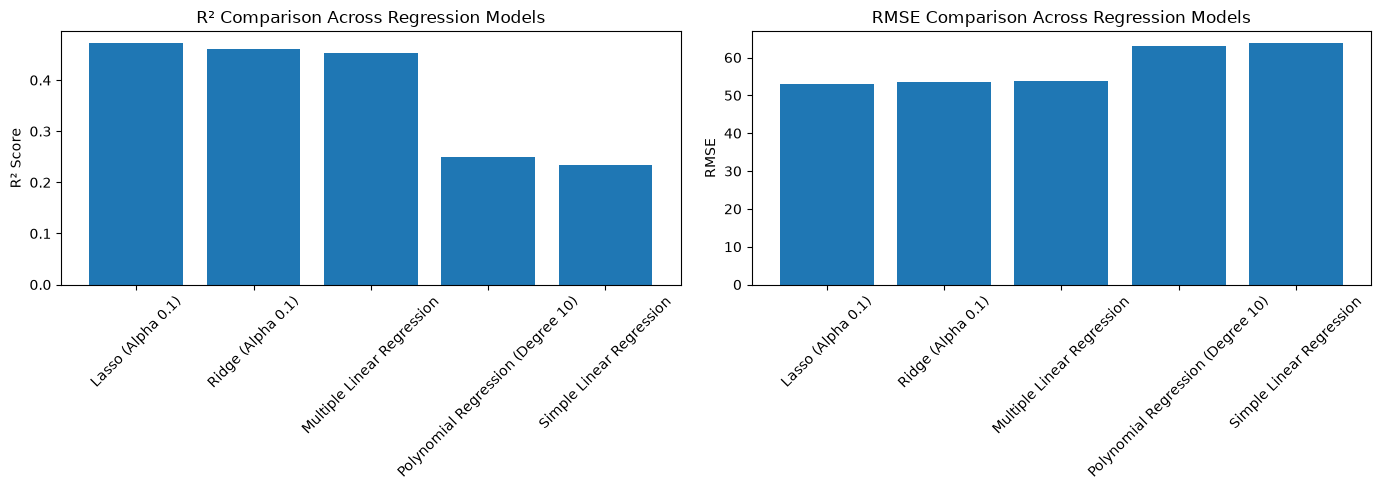

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Compare R²
axes[0].bar(
    final_results["Model"],
    final_results["R²"]
)

axes[0].set_title("R² Comparison Across Regression Models")
axes[0].set_ylabel("R² Score")
axes[0].tick_params(axis="x", rotation=45)

# Compare RMSE
axes[1].bar(
    final_results["Model"],
    final_results["RMSE"]
)

axes[1].set_title("RMSE Comparison Across Regression Models")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [38]:
best_model = final_results.iloc[0]

print("Best Performing Model:", best_model["Model"])
print("MAE:", round(best_model["MAE"], 4))
print("MSE:", round(best_model["MSE"], 4))
print("RMSE:", round(best_model["RMSE"], 4))
print("R²:", round(best_model["R²"], 4))

print("\nModel Ranking:")
for i, row in final_results.iterrows():
    print(f"{i+1}. {row['Model']} - R²: {row['R²']:.4f}")

Best Performing Model: Lasso (Alpha 0.1)
MAE: 42.8544
MSE: 2798.1935
RMSE: 52.898
R²: 0.4719

Model Ranking:
1. Lasso (Alpha 0.1) - R²: 0.4719
2. Ridge (Alpha 0.1) - R²: 0.4609
3. Multiple Linear Regression - R²: 0.4526
4. Polynomial Regression (Degree 10) - R²: 0.2489
5. Simple Linear Regression - R²: 0.2334


## Final Model Comparison and Analysis

In this lab, I implemented Simple Linear Regression, Multiple Linear Regression, Polynomial Regression, Ridge Regression, and Lasso Regression using the Diabetes dataset from scikit-learn.

I evaluated each model using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared (R²). Lower error values indicate better prediction accuracy, while a higher R² generally indicates that the model explains more variation in disease progression.

Simple Linear Regression provided a baseline using BMI as the only independent variable. Multiple Linear Regression used all 10 features to determine whether additional health measurements improved prediction accuracy.

Polynomial Regression demonstrated how increasing model complexity can affect performance. Higher polynomial degrees can capture more complex relationships, but they can also lead to overfitting when the model performs better on training data than on testing data.

Ridge and Lasso Regression demonstrated how regularization can control model complexity. Ridge reduces coefficient magnitudes, while Lasso can eliminate less useful features by shrinking their coefficients to zero. The alpha parameter determines how strongly regularization is applied.

Overall, the results demonstrate that model complexity alone does not guarantee better predictions. Selecting an appropriate model requires balancing prediction accuracy, generalization, and the risk of overfitting.

The Diabetes dataset also demonstrates that disease progression is influenced by multiple health measurements and that regression techniques can identify useful statistical patterns. However, these predictions should not be interpreted as establishing causal relationships.